# HW1 · Part 5. 왜곡 보정 직접 구현 (15점 + 보너스 5 · 예상 3–4시간)

**배포본:** v5 (2026-10-20)

**목표** — Part 2 의 k₁ k₂ 로 영상 · 좌표의 왜곡을 직접 제거(역방향 매핑 · 반복 역왜곡)하고 OpenCV 와 비교. 건물 사진의 직선이 얼마나 곧아졌는지 수치로. MVG 식 (7.7) 의 κ 와 OpenCV k 가 **환산되지 않는** 이유를 수치 맞춤으로 확인

**참고** — MVG 2판 §7.4 (방사 왜곡 (7.7) · Example 7.3 · 7.4 · Table 7.3 · plumb-line), OpenCV calib3d 문서 (Brown–Conrady 모델 · `undistort` · `remap` · `fisheye`)

**TODO** — `distort_normalized`(Part 2 복사) · `undistort_points_iter` · `undistort_pixels` · `undistort_image_backward` · `undistort_image_forward` · `line_fit_residual` · `fit_opencv_k_to_mvg` (7개)

**OpenCV 허용** — 비교용 `cv2.undistort` · `cv2.undistortPoints` · `cv2.initUndistortRectifyMap/remap`(비교만). 5.4 보너스의 `cv2.fisheye.calibrate` · `cv2.calibrateCamera`, 보너스 잔차 비교를 위한 제공 코드의 `cv2.projectPoints` · `cv2.fisheye.projectPoints`

> **허용 · 금지** — NumPy · SciPy · Matplotlib 자유. OpenCV 는 각 Part 안내에 "허용" 으로 적힌 함수만(코너 검출 · `findHomography` · 검증용 비교). 
> `TODO` 로 표시된 함수를 OpenCV 호출로 대체하면 해당 항목 0점. 

In [1]:
# ---- 공통 설정 (HW1 v5 · 모든 노트북에서 같은 설정 파일 사용) ----
import os, sys, json, glob, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'hw1_config.json').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'hw1_config.json').is_file():
    raise FileNotFoundError('HW1 폴더 또는 notebooks 폴더에서 실행하세요: hw1_config.json 을 찾을 수 없습니다.')
sys.path.insert(0, str(ROOT))
from hw1lib import geometry as G, synth as S, exif as E, board as Bd, io_utils as IO, checks as CK, click_tool as CT
# 데모 전환은 HW1/hw1_config.json 의 mode 만 "demo" 로 변경하고 각 노트북의 이 셀을 다시 실행.
cfg = IO.load_config(ROOT)
DATA, RESULTS = cfg['DATA'], cfg['RESULTS']
IO.RESULTS = RESULTS
def load_corners_checked(name):
    """현재 설정과 저장 코너 파일의 검출 배율이 같은지 확인."""
    det = Bd.load_corners(IO.rpath(name))
    if not np.isclose(det['scale'], cfg['SCALE'], rtol=0, atol=1e-12):
        raise ValueError(f"{name}: 저장 배율 {det['scale']}과 현재 설정 scale={cfg['SCALE']}이 다릅니다. Part 0부터 다시 실행하세요.")
    return det
os.makedirs(RESULTS, exist_ok=True)
# 서로 다른 데이터의 결과를 같은 폴더에 섞지 않음. 상대 경로로 기록하여 제출 폴더 이동은 허용.
context = dict(mode=cfg['mode'], data=os.path.relpath(DATA, ROOT), version=5)
context_path = IO.rpath('dataset_context.json')
if os.path.exists(context_path):
    if IO.load_json(context_path) != context:
        raise ValueError('결과 폴더의 데이터 출처가 현재 설정과 다릅니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
elif any(not p.name.startswith('.') for p in Path(RESULTS).iterdir()):
    raise ValueError('출처 기록이 없는 기존 결과가 있습니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
IO.save_json(context_path, context)
np.set_printoptions(precision=4, suppress=True)
import matplotlib
_fonts = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Freesentation']:
    if _f in _fonts:
        matplotlib.rcParams['font.family'] = _f; break
matplotlib.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', message='Glyph')
%matplotlib inline
print('mode =', cfg['mode'], '\nDATA =', DATA, '\nRESULTS =', RESULTS)


mode = student 
DATA = /home/shw/3dvision/data 
RESULTS = /home/shw/3dvision/results


In [2]:
import cv2, time
K_z, kinfo = IO.load_K('K.json'); dist_z, _ = IO.load_dist('dist.json')
print('K · dist 출처:', kinfo['source'], ' dist =', dist_z)
img = E.load_image(os.path.join(DATA, 'building', 'b1.jpg'))[:, :, ::-1].copy()
H, W = img.shape[:2]
K_z = IO.rescale_K_for_image(K_z, kinfo['image_size'], (W, H))
print('image', W, 'x', H, '— K를 이 해상도로 변환함')

K · dist 출처: zhang_scratch_setC  dist = [ 0.071  -0.0982  0.      0.      0.    ]
image 4000 x 3000 — K를 이 해상도로 변환함


## 5.1 언디스토션 — 역방향 매핑 · 순방향 매핑 · 좌표 역왜곡 (8점: 역방향 3 · 순방향 1 · 반복 역왜곡 2 · cv2 비교 1 · 질문 5.1 1)

In [3]:
# ==============================================================================
# TODO  distort_normalized
# 참조: Brown–Conrady 왜곡 모델 (OpenCV calib3d 문서, 계수 순서 k1, k2, p1, p2, k3)
# r² = x² + y²,  방사 = 1 + k1 r² + k2 r⁴ + k3 r⁶
# x_d = x · 방사 + 2 p1 x y + p2 (r² + 2x²),   y_d = y · 방사 + p1 (r² + 2y²) + 2 p2 x y
# 정규화 좌표(K 적용 전)에서 정의됨 — 픽셀 좌표에 적용하면 안 됨 (Part 6 함정 문항).  배열 입력 지원
# Part 2 에서 작성한 것을 복사
# ==============================================================================
def distort_normalized(xn, yn, dist):
    """Brown–Conrady 순방향 (정규화 좌표) — OpenCV 순서 (k1, k2, p1, p2, k3)."""
    # ---- 여기에 작성 ----
    d = np.zeros(5)
    dd = np.ravel(np.asarray(dist, float))[:5]
    d[:dd.size] = dd
    k1, k2, p1, p2, k3 = d
    x, y = np.asarray(xn, float), np.asarray(yn, float)
    r2 = x * x + y * y
    rad = 1 + k1 * r2 + k2 * r2 ** 2 + k3 * r2 ** 3
    xd = x * rad + 2 * p1 * x * y + p2 * (r2 + 2 * x * x)
    yd = y * rad + p1 * (r2 + 2 * y * y) + 2 * p2 * x * y
    return xd, yd


In [4]:
# 제공 — 그레이스케일 (H,W) 및 컬러 (H,W,C) 이중선형 보간
# 좌표 배열 us, vs는 같은 모양. 결과는 좌표 모양 뒤에 채널 차원이 붙음.
def bilinear_sample(img, us, vs):
    """영상 경계 안에서는 보간하고 밖은 0. 픽셀 값의 단위(예: 0–255)는 유지."""
    I = np.asarray(img, dtype=float)
    if I.ndim not in (2, 3):
        raise ValueError('img는 (H,W) 또는 (H,W,C)여야 합니다.')
    H_, W_ = I.shape[:2]
    us, vs = np.broadcast_arrays(np.asarray(us, float), np.asarray(vs, float))
    valid = np.isfinite(us) & np.isfinite(vs) & (us >= 0) & (us <= W_ - 1) & (vs >= 0) & (vs <= H_ - 1)
    uc = np.clip(np.where(valid, us, 0), 0, W_ - 1)
    vc = np.clip(np.where(valid, vs, 0), 0, H_ - 1)
    u0, v0 = np.floor(uc).astype(int), np.floor(vc).astype(int)
    u1, v1 = np.minimum(u0 + 1, W_ - 1), np.minimum(v0 + 1, H_ - 1)
    a, b = uc - u0, vc - v0
    if I.ndim == 3:
        a, b = a[..., None], b[..., None]
        valid = valid[..., None]
    out = ((1 - a) * (1 - b) * I[v0, u0] + a * (1 - b) * I[v0, u1]
           + (1 - a) * b * I[v1, u0] + a * b * I[v1, u1])
    return np.where(valid, out, 0.0)


In [5]:
# ==============================================================================
# TODO  undistort_points_iter
# 참조: 고정점 반복 (OpenCV `undistortPoints` 가 쓰는 방식)
# x_d = x·rad(x) + Δ_tan(x) 를 x 에 대해 풀어야 하는데 닫힌 해가 없음 → x^(0) = x_d 에서 시작해  x^(k+1) = (x_d − Δ_tan(x^(k))) / rad(x^(k))  반복 (보통 5–10회)
# rad = 1 + k1 r² + k2 r⁴ + k3 r⁶,  Δ_tan 은 distort_normalized 의 접선 항.  배열 입력.  반환 (x_n, y_n)
# 검증: cv2.undistortPoints 와 1e-3 px 이내 — checks.check_undistort_points
# ==============================================================================
def undistort_points_iter(xd, yd, dist, iters=10):
    """좌표 역왜곡 (정규화 좌표) — 고정점 반복: x ← (x_d − Δ_tan(x)) / rad(x)."""
    # ---- 여기에 작성 ----
    d = np.zeros(5)
    dd = np.ravel(np.asarray(dist, float))[:5]
    d[:dd.size] = dd
    k1, k2, p1, p2, k3 = d
    xd, yd = np.asarray(xd, float), np.asarray(yd, float)
    x, y = xd.copy(), yd.copy()                           # x^(0) = x_d
    for _ in range(iters):
        r2 = x * x + y * y
        rad = 1 + k1 * r2 + k2 * r2 ** 2 + k3 * r2 ** 3
        dx = 2 * p1 * x * y + p2 * (r2 + 2 * x * x)       # Δ_tan
        dy = p1 * (r2 + 2 * y * y) + 2 * p2 * x * y
        x, y = (xd - dx) / rad, (yd - dy) / rad
    return x, y


# ==============================================================================
# TODO  undistort_pixels
# 픽셀 (N, 2) → K⁻¹ → undistort_points_iter → K_new (None 이면 K) → 픽셀 (N, 2).  cv2.undistortPoints(..., P=K) 와 같은 역할
# ==============================================================================
def undistort_pixels(uv, K, dist, K_new=None):
    """픽셀 (N, 2) 왜곡 좌표 → 보정 픽셀 (N, 2)  (cv2.undistortPoints 와 비교용)."""
    # ---- 여기에 작성 ----
    uv = np.asarray(uv, float).reshape(-1, 2)
    K = np.asarray(K, float)
    K_new = K if K_new is None else np.asarray(K_new, float)
    xh = np.linalg.solve(K, G.to_homog(uv.T))             # K⁻¹ (왜곡 정규화 좌표)
    xn, yn = undistort_points_iter(xh[0] / xh[2], xh[1] / xh[2], dist)
    out = K_new @ np.vstack([xn, yn, np.ones_like(xn)])
    return (out[:2] / out[2]).T


# ==============================================================================
# TODO  undistort_image_backward
# 참조: 역방향 매핑 · 이중선형 보간 (OpenCV `undistort` · `remap` 문서), 9월 HW1 Part B TODO 2
# 결과 영상의 픽셀 (u, v) 마다 "원본의 어디서 가져올지" 를 계산: (u, v) → K_new⁻¹ → (x_n, y_n) → distort_normalized → (x_d, y_d) → K → (u_s, v_s)
# ※ 역방향에는 역함수가 아니라 "순방향 D" 가 들어감 — 그래서 반복이 필요 없음
# (u_s, v_s) 는 실수 → bilinear_sample 로 보간 (컬러 배열도 직접 지원; 채널별 호출도 가능).  K_new 가 None 이면 K.  반환: 원본과 같은 크기의 보정 영상 (밝기 0–255, uint8 또는 float)
# 검증: cv2.undistort 와의 밝기 차 평균 < 1 (보간 구현 차이) — checks.check_undistort_backward
# ==============================================================================
def undistort_image_backward(img_d, K, dist, K_new=None):
    """역방향 매핑 언디스토션 (9월 HW1 Part B): 결과 픽셀 (u, v) → K_new⁻¹ → (x_n, y_n) → D → (x_d, y_d) → K → 원본 위치 → 보간."""
    # ---- 여기에 작성 ----
    img = np.asarray(img_d)
    I = img.astype(float)                                 # 한 번만 float 변환
    K = np.asarray(K, float)
    K_new = K if K_new is None else np.asarray(K_new, float)
    Kn_inv = np.linalg.inv(K_new)
    Hh, Ww = img.shape[:2]
    out = np.zeros(img.shape, float)
    us = np.arange(Ww, dtype=float)
    step = 256
    for v0 in range(0, Hh, step):
        U, V = np.meshgrid(us, np.arange(v0, min(v0 + step, Hh), dtype=float))
        w = Kn_inv[2, 0] * U + Kn_inv[2, 1] * V + Kn_inv[2, 2]
        xn = (Kn_inv[0, 0] * U + Kn_inv[0, 1] * V + Kn_inv[0, 2]) / w   # 결과 픽셀 → K_new⁻¹
        yn = (Kn_inv[1, 0] * U + Kn_inv[1, 1] * V + Kn_inv[1, 2]) / w
        xd, yd = distort_normalized(xn, yn, dist)                       # 순방향 D
        u_s = K[0, 0] * xd + K[0, 1] * yd + K[0, 2]                     # → K → 원본 위치
        v_s = K[1, 1] * yd + K[1, 2]
        out[v0:v0 + U.shape[0]] = bilinear_sample(I, u_s, v_s)          # 이중선형 보간으로 '가져옴'
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


# ==============================================================================
# TODO  undistort_image_forward
# 순방향 매핑 — 원본 픽셀마다 목적지를 계산해 값을 "던짐" (역방향과의 차이가 질문 5.1 (1)(2))
# 원본 (u, v) → K⁻¹ → (x_d, y_d) → undistort_points_iter → (x_n, y_n) → K → 목적지 (반올림) → 값 복사.  밖으로 나가는 픽셀은 버림
# 값을 못 받은 픽셀(구멍) 수를 세어 함께 반환 (NaN 으로 초기화하면 쉬움).  반환 (영상, holes). 영상의 밝기 단위는 입력과 같은 0–255; 빈 픽셀은 NaN 또는 0, holes는 픽셀 수
# ==============================================================================
def undistort_image_forward(img_d, K, dist):
    """순방향 매핑 — 원본 픽셀마다 이상 위치로 값을 '보냄'. 구멍 수를 함께 반환."""
    # ---- 여기에 작성 ----
    img = np.asarray(img_d)
    K = np.asarray(K, float)
    Kinv = np.linalg.inv(K)
    Hh, Ww = img.shape[:2]
    out = np.full(img.shape, np.nan)                      # 못 받은 픽셀 = NaN
    filled = np.zeros((Hh, Ww), bool)
    us = np.arange(Ww, dtype=float)
    step = 256
    for v0 in range(0, Hh, step):
        vs = np.arange(v0, min(v0 + step, Hh))
        U, V = np.meshgrid(us, vs.astype(float))
        w = Kinv[2, 0] * U + Kinv[2, 1] * V + Kinv[2, 2]
        xd = (Kinv[0, 0] * U + Kinv[0, 1] * V + Kinv[0, 2]) / w         # 원본 픽셀 → K⁻¹
        yd = (Kinv[1, 0] * U + Kinv[1, 1] * V + Kinv[1, 2]) / w
        xn, yn = undistort_points_iter(xd, yd, dist)                    # 역왜곡 (반복)
        uf = K[0, 0] * xn + K[0, 1] * yn + K[0, 2]                      # → K → 목적지
        vf = K[1, 1] * yn + K[1, 2]
        ud = np.where(np.isfinite(uf), np.rint(uf), -1).astype(np.int64)   # 반올림
        vd = np.where(np.isfinite(vf), np.rint(vf), -1).astype(np.int64)
        ok = (ud >= 0) & (ud < Ww) & (vd >= 0) & (vd < Hh)                 # 밖으로 나가면 버림
        out[vd[ok], ud[ok]] = img[v0:v0 + len(vs)][ok]                     # 값을 '던짐'
        filled[vd[ok], ud[ok]] = True
    holes = int((~filled).sum())
    return out, holes


역방향: 우리 1.42 s, cv2.undistort 0.049 s,  밝기 차 평균 0.027 (유효 영역), 최대 3.0


순방향: 구멍 258643 픽셀 (2.16 %)
좌표 역왜곡: cv2.undistortPoints 와 최대 차 2.85e-03 px;  모서리 이동량 28.0 px


  [OK]   역방향 언디스토션 — cv2.undistort 대비 평균 밝기 차 0.032
  [OK]   좌표 역왜곡 (반복) — cv2.undistortPoints 대비 최대 차 5.04e-05 px


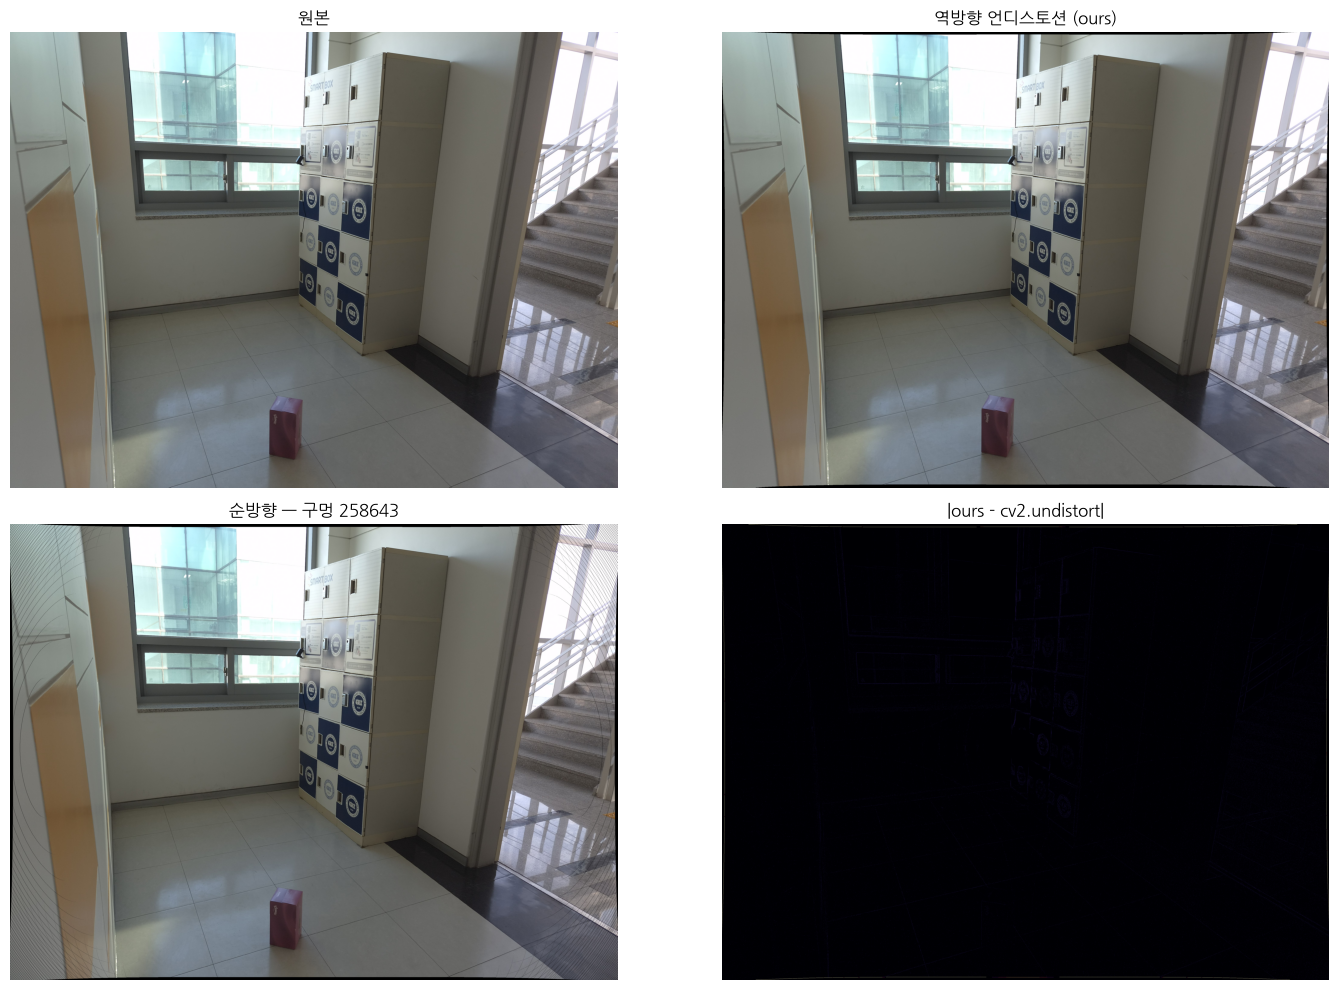

In [6]:
t0 = time.time(); und = undistort_image_backward(img, K_z, dist_z); t_ours = time.time() - t0
t0 = time.time(); ref = cv2.undistort(img, K_z, dist_z); t_cv = time.time() - t0
m = und.sum(axis=2) > 0
diff = np.abs(und.astype(float) - ref.astype(float)).mean(axis=2)
print('역방향: 우리 %.2f s, cv2.undistort %.3f s,  밝기 차 평균 %.3f (유효 영역), 최대 %.1f' % (t_ours, t_cv, diff[m].mean(), diff[m].max()))
fwd, holes = undistort_image_forward(img, K_z, dist_z)
print('순방향: 구멍 %d 픽셀 (%.2f %%)' % (holes, holes / (W * H) * 100))
pts = np.array([[20.0, 20.0], [W - 20.0, H - 20.0], [W / 2, H / 2], [W - 20.0, 20.0]])
ours = undistort_pixels(pts, K_z, dist_z); cvp = cv2.undistortPoints(pts.reshape(-1, 1, 2), K_z, dist_z, P=K_z).reshape(-1, 2)
print('좌표 역왜곡: cv2.undistortPoints 와 최대 차 %.2e px;  모서리 이동량 %.1f px' % (np.abs(ours - cvp).max(), np.linalg.norm(ours[1] - pts[1])))
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
to_display = lambda a: np.clip(np.nan_to_num(np.asarray(a, float), nan=0.0, posinf=255.0, neginf=0.0), 0, 255).astype(np.uint8)
ax[0, 0].imshow(img); ax[0, 0].set_title('원본'); ax[0, 1].imshow(to_display(und)); ax[0, 1].set_title('역방향 언디스토션 (ours)')
ax[1, 0].imshow(to_display(fwd)); ax[1, 0].set_title(f'순방향 — 구멍 {holes}'); ax[1, 1].imshow(diff, cmap='magma', vmax=10); ax[1, 1].set_title('|ours - cv2.undistort|')
for a in ax.ravel(): a.set_axis_off()
fig.tight_layout(); fig.savefig(IO.rpath('part5_undistort.png'), dpi=100)
stats = dict(time_ours=t_ours, time_cv=t_cv, mean_abs_diff=float(diff[m].mean()), holes_forward=holes, max_point_diff=float(np.abs(ours - cvp).max()))
CK.check_undistort_backward(undistort_image_backward); CK.check_undistort_points(undistort_pixels);

**보고서 질문 5.1** — (1) 역방향 매핑에는 왜 D⁻¹ 가 아니라 D 가 들어가는가 (2) 순방향의 구멍은 어디에 몰리는가, 왜 (3) 보정 영상이 원본보다 흐린 이유와 "좌표만 보정" 이 SfM 에서 선호되는 이유 (MVG §7.4 Example 7.4)

## 5.2 직선 곧음 지표 — plumb-line (3점)
건물의 긴 직선 에지 3개(가장자리를 지나는 것으로)에 6–8 점씩 클릭합니다. 보정 전 · 후 직선 맞춤 잔차(RMS px)를 비교합니다.

In [7]:
plumb_json = os.path.join(DATA, 'building', 'b1_plumb.json')
if not os.path.exists(plumb_json):
    get_ipython().run_line_magic('matplotlib', 'widget')
    pc = CT.NotebookClicker(os.path.join(DATA, 'building', 'b1.jpg'), kind='polylines', spec={'edge1': 8, 'edge2': 8, 'edge3': 8}, title='에지 위의 점').show()
else:
    print('이미 있음:', plumb_json)

이미 있음: /home/shw/3dvision/data/building/b1_plumb.json


In [8]:
if not os.path.exists(plumb_json):
    pc.save(plumb_json)
    get_ipython().run_line_magic('matplotlib', 'inline')

In [9]:
# ==============================================================================
# TODO  line_fit_residual
# 참조: MVG §7.4 (직선은 직선 — plumb-line 방법)
# 점 (N, 2) 의 중심을 빼고 SVD → 최소 특이값 방향 n 이 직선의 법선 (총최소제곱).  각 점의 수직 거리 = (P − c)·n → RMS (px)
# 보정 전 · 후의 같은 에지에서 이 값을 비교 = 왜곡 모델이 직선을 얼마나 되살렸는지
# ==============================================================================
def line_fit_residual(pts):
    """점 (N, 2) 에 직선을 최소제곱(총최소제곱, SVD)으로 맞춘 뒤 수직 거리의 RMS (px)  — plumb-line 곧음 지표 (MVG §7.4)."""
    # ---- 여기에 작성 ----
    P = np.asarray(pts, float).reshape(-1, 2)
    Pc = P - P.mean(axis=0)
    _, _, Vt = np.linalg.svd(Pc, full_matrices=False)
    n = Vt[-1]                                            # 최소 특이값 방향 = 법선 (총최소제곱)
    d = Pc @ n                                            # 수직 거리
    return float(np.sqrt(np.mean(d ** 2)))


In [10]:
pl = IO.load_json(os.path.join(DATA, 'building', 'b1_plumb.json'))
if pl['image'] != 'b1.jpg':
    raise ValueError('plumb-line 클릭 JSON은 현재 보정한 b1.jpg와 같은 사진이어야 합니다.')
print('%-8s %10s %10s' % ('edge', 'before', 'after'))
res = {}
for name, pts in pl['polylines'].items():
    P = np.array(pts, float); Pu = undistort_pixels(P, K_z, dist_z)
    r0, r1 = line_fit_residual(P), line_fit_residual(Pu); res[name] = (r0, r1)
    print('%-8s %10.2f %10.2f   px' % (name, r0, r1))
stats['plumb'] = res
CK.check_line_residual(line_fit_residual);

edge         before      after
edge1          0.18       1.50   px
edge2          1.52       0.76   px
edge3          1.58       1.89   px
  [OK]   직선 곧음 지표 — 직선 0.48 px, 휜 선 5.92 px


## 5.3 MVG κ ↔ OpenCV k — 환산 함정 (4점: 표 2 · 질문 5.3 2)
MVG Example 7.3: 640 × 480, κ₁ = 0.103689, κ₂ = 0.00487908, κ₃ = 0.00116894, κ₄ = 0.000841614, 중심 (321.87, 241.18), 보정식 x̂ = x_c + L(r)(x − x_c). 책은 r 의 단위를 명시하지 않으므로 **이 과제에서는 평균 반크기 (640+480)/4 = 280 px 단위**로 둡니다 (그래야 가장자리 보정량이 책의 "약 30 px" 과 맞음).
OpenCV k₁ 로 "환산" 하라는 요청에 LLM 들은 보통 단위 환산 계수 하나를 곱해 답합니다. 실제로 해 보세요: f 를 500 · 700 · 1000 px 로 바꿔 가며 k 를 맞추고, 잔차와 함께 표로.

In [11]:
# 제공 — MVG (7.7) 의 L(r)
def mvg_correction_L(r, kappas):
    """MVG (7.7) 보정 함수 L(r) = 1 + κ1 r + κ2 r² + …  (MVG §7.4 Example 7.3; r 의 단위는 이 과제에서 '이미지 평균 반크기 (W+H)/4' 로 둠 — 책은 명시하지 않음)."""
    L = np.ones_like(r)
    for i, k in enumerate(kappas, start=1):
        L = L + k * r ** i
    return L


In [12]:
# ==============================================================================
# TODO  fit_opencv_k_to_mvg
# 참조: MVG §7.4 식 (7.7) · Example 7.3, OpenCV 왜곡 모델 — 함정 문항 5.3 의 근거
# MVG (7.7) 보정식: x̂ = x_c + L(r)(x − x_c),  L(r) = 1 + κ1 r + κ2 r² + κ3 r³ + κ4 r⁴ — 측정(왜곡) → 보정 방향, 홀수 차수 포함
#    r 의 단위: 책은 명시하지 않음 — 이 과제에서는 "이미지 평균 반크기 (W+H)/4 = 280 px" 로 둠 (그래야 가장자리 보정량이 책의 "약 30 px" 과 맞음)
# OpenCV: x_d = x (1 + k1 r² + k2 r⁴),  r 은 정규화 좌표(f 로 나눈) 단위 — 이상 → 왜곡 방향, 짝수 차수만
# → 차수 · 방향 · 단위가 모두 달라 κ ↔ k 의 해석적 환산은 없음 (f 조차 Example 7.3 에는 안 나옴).  할 수 있는 것은 "수치 맞춤":
# ① 이미지 격자점 (측정 좌표) 을 만들고 MVG 식으로 보정 좌표를 계산 → (이상 ↔ 측정) 쌍   ② 이상 좌표를 f_px 로 나눠 정규화 (x, y), r_n² = x² + y²
# ③ (측정/f − x) = x (k1 r_n² + k2 r_n⁴) 꼴의 1차식을 x · y 모두 쌓아 최소제곱 → k   ④ 잔차 RMS (px) 로 "얼마나 잘 맞는지" 보고
# 반환 (k (n_dist,), rms_px).  f_px 를 바꾸면 k 가 바뀜을 확인할 것 — 그것이 함정의 핵심
# ==============================================================================
def fit_opencv_k_to_mvg(kappas, image_size, f_px, center=None, n_dist=2):
    """Example 7.3 의 κ(보정, r 단위 = 평균 반크기 (W+H)/4 로 가정) 를 OpenCV (k1, k2)(왜곡, 정규화 좌표) 로 '수치 맞춤' —
    해석적 환산은 존재하지 않음(차수 · 방향 · 단위가 모두 다름). 보정된 점 ↔ 측정점 쌍을 만들어 최소제곱.
    반환: k (n_dist,), 맞춤 잔차 RMS (px)."""
    # ---- 여기에 작성 ----
    W, H = image_size
    c = np.array([(W - 1) / 2, (H - 1) / 2] if center is None else center, float)
    r_unit = (W + H) / 4.0                                # κ 의 r 단위 (평균 반크기)
    # ① 측정(왜곡) 격자점 → MVG (7.7) 보정 → 이상 좌표
    gu, gv = np.meshgrid(np.linspace(0, W - 1, 41), np.linspace(0, H - 1, 31))
    xm = np.column_stack([gu.ravel(), gv.ravel()])        # 측정 픽셀
    dm = xm - c
    L = mvg_correction_L(np.linalg.norm(dm, axis=1) / r_unit, kappas)
    xi = c + L[:, None] * dm                              # 보정(이상) 픽셀
    # ② 정규화 (f_px 로 나눔)
    xn = (xi - c) / f_px                                  # 이상 정규화
    xd = (xm - c) / f_px                                  # 측정 정규화
    rn2 = np.sum(xn ** 2, axis=1)
    # ③ x_d − x = x (k1 r² + k2 r⁴ + …)  — x · y 모두 쌓아 최소제곱
    cols = [rn2 ** (i + 1) for i in range(n_dist)]
    A = np.vstack([np.column_stack([xn[:, 0] * cc for cc in cols]),
                   np.column_stack([xn[:, 1] * cc for cc in cols])])
    rhs = np.concatenate([xd[:, 0] - xn[:, 0], xd[:, 1] - xn[:, 1]])
    k, *_ = np.linalg.lstsq(A, rhs, rcond=None)
    # ④ 맞춘 k 로 이상 → 측정을 예측한 잔차 (px)
    pred = xn * (1 + sum(k[i] * rn2 ** (i + 1) for i in range(n_dist)))[:, None] * f_px + c
    rms = float(np.sqrt(np.mean(np.sum((pred - xm) ** 2, axis=1))))
    return k, rms


In [13]:
kap = [0.103689, 0.00487908, 0.00116894, 0.000841614]
print('주변부(r = 1, 280 px) 보정량: L(1) − 1 = %.4f → %.1f px (책: 30 px)' % (mvg_correction_L(np.array([1.0]), kap)[0] - 1, (mvg_correction_L(np.array([1.0]), kap)[0] - 1) * 280))
print('%6s %10s %10s %10s' % ('f_px', 'k1', 'k2', 'rms(px)'))
tab = {}
for f in (500.0, 700.0, 1000.0):
    k, r = fit_opencv_k_to_mvg(kap, (640, 480), f_px=f, center=(321.87, 241.18))
    tab[f] = (k.tolist(), r); print('%6.0f %10.4f %10.4f %10.3f' % (f, k[0], k[1], r))
stats['mvg_fit'] = tab
IO.save_json(IO.rpath('undistort_stats.json'), stats)

주변부(r = 1, 280 px) 보정량: L(1) − 1 = 0.1106 → 31.0 px (책: 30 px)
  f_px         k1         k2    rms(px)
   500    -0.3689     0.2666      2.224
   700    -0.7230     1.0243      2.224
  1000    -1.4756     4.2661      2.224


'/home/shw/3dvision/results/undistort_stats.json'

**보고서 질문 5.3** — 왜 하나의 환산 계수가 존재하지 않는가 (차수 · 방향 · 단위 · f 의존), 잔차가 남는 이유, 그리고 "같은 렌즈" 를 두 모델로 캘리브레이션하면 어느 쪽이 더 좋은가에 대한 본인 의견 (모델 선택 — 과적합 주의).

## 5.4 보너스 (5점) — 어안 세트가 제공된 경우
`data/fisheye/` 에 어안 카메라의 체커보드 세트가 있으면: (i) 핀홀 + Brown(k₁ k₂ k₃ p₁ p₂) (ii) `cv2.fisheye`(Kannala–Brandt θ_d) 로 같은 세트를 캘리브레이션하고 **가장자리(r > 0.7 r_max) 잔차** 를 비교합니다. 없으면 건너뜁니다.

In [14]:
fe = os.path.join(DATA, 'fisheye')
if os.path.isdir(fe) and E.list_images(fe):
    d = Bd.detect_set(fe, verbose=False)
    objs = [o.astype(np.float32).reshape(-1, 1, 3) for o in d['objpoints']]; imgs = [m.astype(np.float32).reshape(-1, 1, 2) for m in d['imgpoints']]
    Wf, Hf = d['image_size']
    rms_p, Kp, dp, rvp, tvp = cv2.calibrateCamera(objs, imgs, (Wf, Hf), None, None, flags=0)        # 핀홀 + Brown 5계수 (k1 k2 p1 p2 k3)
    Kf = np.eye(3); Df = np.zeros((4, 1))
    rms_f, Kf, Df, rvf, tvf = cv2.fisheye.calibrate([o.reshape(-1, 1, 3).astype(np.float64) for o in d['objpoints']], [m.reshape(-1, 1, 2).astype(np.float64) for m in d['imgpoints']], (Wf, Hf), Kf, Df,
                                                    flags=cv2.fisheye.CALIB_RECOMPUTE_EXTRINSIC | cv2.fisheye.CALIB_FIX_SKEW, criteria=(cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-8))
    rmax = np.hypot(Wf / 2, Hf / 2)
    def edge_resid(proj):
        e_edge, e_center = [], []
        for i, (o, m) in enumerate(zip(d['objpoints'], d['imgpoints'])):
            p = proj(i, o)
            r = np.hypot(m[:, 0] - Wf / 2, m[:, 1] - Hf / 2); e = np.linalg.norm(p - m, axis=1)
            e_edge += list(e[r > 0.7 * rmax]); e_center += list(e[r <= 0.7 * rmax])
        return np.sqrt(np.mean(np.square(e_edge))) if e_edge else np.nan, np.sqrt(np.mean(np.square(e_center)))
    pin = edge_resid(lambda i, o: cv2.projectPoints(o.astype(np.float32), rvp[i], tvp[i], Kp, dp)[0].reshape(-1, 2))
    fis = edge_resid(lambda i, o: cv2.fisheye.projectPoints(o.reshape(-1, 1, 3).astype(np.float64), rvf[i], tvf[i], Kf, Df)[0].reshape(-1, 2))
    print('pinhole+Brown(5): RMS %.3f, 가장자리 %.3f / 중앙 %.3f px' % (rms_p, *pin)); print('fisheye (KB):     RMS %.3f, 가장자리 %.3f / 중앙 %.3f px' % (rms_f, *fis))
else:
    print('data/fisheye 없음 — 보너스 생략')

data/fisheye 없음 — 보너스 생략


## 보고서에 넣을 것 (Part 5, 슬라이드 3장)
1. 역방향/순방향 결과 + cv2 와의 차 영상 + 질문 5.1 답
2. plumb-line 표(에지별 전/후) + 에지 확대 그림
3. κ → k 수치 맞춤 표(f 별) + 질문 5.3 답 (+ 보너스)

In [15]:
CK.run_all(globals());

  [OK]   역방향 언디스토션 — cv2.undistort 대비 평균 밝기 차 0.032
  [OK]   좌표 역왜곡 (반복) — cv2.undistortPoints 대비 최대 차 5.04e-05 px
  [OK]   직선 곧음 지표 — 직선 0.48 px, 휜 선 5.92 px
